In [1]:
# import all library needed only

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.preprocessing import PolynomialFeatures
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import classification_report

In [2]:
# import dataset
wine = pd.read_csv('Dataset/white_wine.csv')
wine.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.0,0.27,0.36,20.7,0.045,45.0,170.0,1.0010,3.00,0.45,8.8,6.0
1,6.3,0.30,0.34,1.6,0.049,14.0,132.0,0.9940,3.30,0.49,9.5,6.0
2,8.1,0.28,0.40,6.9,0.050,30.0,97.0,0.9951,3.26,0.44,10.1,6.0
3,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6.0
4,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6.0


In [5]:
wine['quality'].describe()

count    519.000000
mean       5.805395
std        0.880226
min        3.000000
25%        5.000000
50%        6.000000
75%        6.000000
max        8.000000
Name: quality, dtype: float64

In [7]:
# let's check the target proportion
wine['label'] = np.where(wine['quality']>6,1,0)
wine['label'].value_counts(normalize=True)

label
0    0.811538
1    0.188462
Name: proportion, dtype: float64

In [10]:
wine.isna().sum()

fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      1
sulphates               1
alcohol                 0
quality                 1
label                   0
dtype: int64

In [9]:
# fillna in alcohol
wine['alcohol'].fillna(wine['alcohol'].median(),inplace=True)

In [11]:
# feature selection and splitting
X = wine[['alcohol','density']]
y = wine['label']

# splitting
X_train,X_test,y_train,y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=0,
    stratify=y # stratify used for classification
)

In [18]:
# model without polynomial 
logreg = LogisticRegression()
logreg.fit(X_train,y_train)

y_pred = logreg.predict(X_test)
print('Perfomance \n', classification_report(y_test,y_pred))

Perfomance 
               precision    recall  f1-score   support

           0       0.86      0.95      0.90        84
           1       0.64      0.35      0.45        20

    accuracy                           0.84       104
   macro avg       0.75      0.65      0.68       104
weighted avg       0.82      0.84      0.82       104



In [19]:
# fit the polynomial to X_train and X_test
poly = PolynomialFeatures(degree=3, interaction_only=False, include_bias=False)
poly.fit(X_train)
X_train_poly = poly.transform(X_train)
X_test_poly = poly.transform(X_test)

# define the model
logreg = LogisticRegression()
logreg.fit(X_train_poly,y_train)

# predict
y_pred = logreg.predict(X_test_poly)
print('Perfomance in test using polynomal \n',classification_report(y_test,y_pred))

Perfomance in test using polynomal 
               precision    recall  f1-score   support

           0       0.92      1.00      0.96        84
           1       1.00      0.65      0.79        20

    accuracy                           0.93       104
   macro avg       0.96      0.82      0.87       104
weighted avg       0.94      0.93      0.93       104



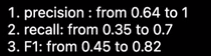

In [20]:
bankloan = pd.read_csv('Dataset/bankloan.csv')

In [21]:
# feature selection
X = bankloan[['employ','debtinc','creddebt','othdebt']]
y = bankloan['default']

In [23]:
# check target proportion
y.value_counts(normalize=True)

default
0    0.738571
1    0.261429
Name: proportion, dtype: float64

In [24]:
# split
X_train_val,X_test, y_train_val, y_test = train_test_split(
    X,
    y,
    stratify=y,
    test_size=0.2,
    random_state=0
)

# No treatment

In [25]:
# model fit
model = LogisticRegression()
model.fit(X_train_val,y_train_val)

# model_predict
y_pred = model.predict(X_test)
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.84      0.96      0.90       103
           1       0.82      0.49      0.61        37

    accuracy                           0.84       140
   macro avg       0.83      0.72      0.75       140
weighted avg       0.83      0.84      0.82       140



# Undersampling

In [45]:
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler, NearMiss

rus = RandomUnderSampler(random_state=0)
X_under, y_under = rus.fit_resample(X_train_val, y_train_val)

In [46]:
# define new model
model_under = LogisticRegression()
model_under.fit(X_under,y_under)
y_pred = model_under.predict(X_test)
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.93      0.74      0.82       103
           1       0.53      0.84      0.65        37

    accuracy                           0.76       140
   macro avg       0.73      0.79      0.74       140
weighted avg       0.82      0.76      0.78       140



# Algorithm Based

In [47]:
# define a new model
model_balanced = LogisticRegression(class_weight='balanced',random_state=0)
model_balanced.fit(X_train_val,y_train_val)

# predict
y_pred = model_balanced.predict(X_test)
print(classification_report(y_test,y_pred))


              precision    recall  f1-score   support

           0       0.91      0.75      0.82       103
           1       0.53      0.78      0.63        37

    accuracy                           0.76       140
   macro avg       0.72      0.77      0.72       140
weighted avg       0.81      0.76      0.77       140



# Implement resampling in Algorithm Chain

In [64]:
from imblearn.pipeline import Pipeline
from sklearn.model_selection import cross_val_score,StratifiedKFold, GridSearchCV, RandomizedSearchCV

smote = SMOTE(random_state=0)
model = LogisticRegression(random_state=0)

estimator = Pipeline([
    ('balancing',smote),
    ('clf', model)
])

# define hyperparameter space
hyperparameter_space = {
    'clf__C':[100,1,0.1,0.01,0.0001],
    'clf__solver':['liblinear','newton-cg']
}

# stratified cross validation
skf = StratifiedKFold(n_splits=5)

# hyperparameter tuning
grid_search = GridSearchCV(
    estimator=estimator,
    param_grid = hyperparameter_space,
    cv = skf,
    scoring= 'f1',
    n_jobs = -1
)

In [65]:
grid_search.fit(X_train_val,y_train_val)

GridSearchCV(cv=StratifiedKFold(n_splits=5, random_state=None, shuffle=False),
             estimator=Pipeline(steps=[('balancing', SMOTE(random_state=0)),
                                       ('clf',
                                        LogisticRegression(random_state=0))]),
             n_jobs=-1,
             param_grid={'clf__C': [100, 1, 0.1, 0.01, 0.0001],
                         'clf__solver': ['liblinear', 'newton-cg']},
             scoring='f1')

In [66]:
print('best score:',grid_search.best_score_)
print('best params:',grid_search.best_params_)

best score: 0.6179144825088688
best params: {'clf__C': 0.1, 'clf__solver': 'liblinear'}


# Model without tuning

In [69]:
# resampling
smote = SMOTE(random_state=0)

# model
model = LogisticRegression(random_state=0)

estimator = Pipeline([
    ('balancing',smote),
    ('clf',model)
])

estimator.fit(X_train_val,y_train_val)
y_pred = estimator.predict(X_test)
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.91      0.76      0.83       103
           1       0.54      0.78      0.64        37

    accuracy                           0.76       140
   macro avg       0.72      0.77      0.73       140
weighted avg       0.81      0.76      0.78       140



# Model with tuning

In [70]:
grid_search.best_estimator_.fit(X_train_val,y_train_val)
y_pred = grid_search.best_estimator_.predict(X_test)
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.92      0.75      0.82       103
           1       0.54      0.81      0.65        37

    accuracy                           0.76       140
   macro avg       0.73      0.78      0.73       140
weighted avg       0.82      0.76      0.78       140

